# 04 - Evaluasi Model

Notebook ini mengevaluasi model dari `03_GaussianNB` dengan metrik
multi-kelas standar, lalu secara khusus **menguji langsung** apakah
model terjebak memprediksi sumber data alih-alih tipe diabetes --
kekhawatiran yang diajukan pada `01_EDA` bagian 3.2 dan 7.


In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import split_features_target, RANDOM_STATE, TEST_SIZE
from src.evaluate import evaluate_predictions
from src.merge import DIAGNOSIS_LABELS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

model = joblib.load(MODELS_DIR / "gnb_diagnosis.joblib")
df_gabungan = pd.read_csv(PROCESSED_DIR / "merged_diagnosis.csv")
df_model = df_gabungan.drop(columns=["SumberData"])

print("Kelas yang dipelajari model:", list(model.classes_))


Kelas yang dipelajari model: [np.str_('Gestasional'), np.str_('Normal'), np.str_('Tipe 2')]


## Membentuk Ulang Data Uji


In [2]:
X, y = split_features_target(df_model, target_col="DiagnosisType")
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df_model.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
y_pred = model.predict(X_test)

print(f"Data uji: {len(y_test)} sampel")
print(y_test.value_counts().reindex(DIAGNOSIS_LABELS))


Data uji: 859 sampel
DiagnosisType
Normal         531
Tipe 2          54
Gestasional    274
Name: count, dtype: int64


## Metrik Klasifikasi


In [3]:
metrik = evaluate_predictions(y_test, y_pred, labels=DIAGNOSIS_LABELS)
print("Akurasi      :", metrik["akurasi"])
print("Precision makro:", metrik["precision_macro"])
print("Recall makro   :", metrik["recall_macro"])
print("F1 makro       :", metrik["f1_macro"])
print()
pd.DataFrame(metrik["per_kelas"]).T


Akurasi      : 0.8591
Precision makro: 0.7616
Recall makro   : 0.7936
F1 makro       : 0.7708



             precision  recall  f1_score  support
Normal          0.8824  0.9040    0.8930    531.0
Tipe 2          0.4737  0.6667    0.5538     54.0
Gestasional     0.9289  0.8102    0.8655    274.0

`Normal` dan `Gestasional` (kelas besar, didukung ribuan sampel)
berperforma kuat. `Tipe 2` jauh lebih lemah (precision & recall lebih
rendah) -- wajar, hanya didukung puluhan sampel uji akibat
ketidakseimbangan prior yang sudah dibahas pada `03_GaussianNB`.


## Confusion Matrix (3x3)


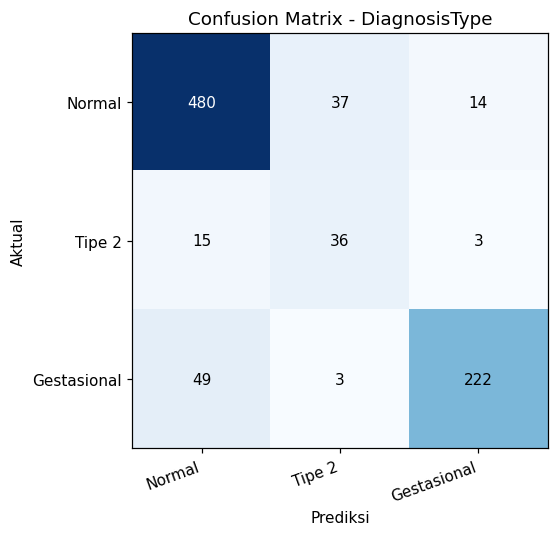

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5))
cm = metrik["confusion_matrix"]
n = len(DIAGNOSIS_LABELS)
ax.imshow(cm, cmap="Blues")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(DIAGNOSIS_LABELS, rotation=20, ha="right")
ax.set_yticklabels(DIAGNOSIS_LABELS)
nilai_maks = max(max(row) for row in cm) or 1
for i in range(n):
    for j in range(n):
        warna = "white" if cm[i][j] > nilai_maks / 2 else "black"
        ax.text(j, i, cm[i][j], ha="center", va="center", color=warna)
ax.set_title("Confusion Matrix - DiagnosisType")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()


## Pengujian Langsung: Apakah Model Menebak Sumber Data?

`01_EDA` menduga model berisiko mempelajari perbedaan sumber data
(Pima vs GDM), bukan murni tipe diabetes, karena `BMI` berbeda
sistematis antar sumber bahkan pada kelas `Normal` yang sama. Bagian
ini mengujinya langsung: latih classifier terpisah yang hanya
memprediksi `SumberData` (bukan `DiagnosisType`) dari kelima fitur
yang sama, dan lihat seberapa mudah itu dilakukan.


In [5]:
from sklearn.naive_bayes import GaussianNB

sumber_test = df_gabungan.loc[idx_test, "SumberData"]
sumber_train = df_gabungan.loc[idx_train, "SumberData"]

model_sumber = GaussianNB()
model_sumber.fit(X_train, sumber_train)
akurasi_sumber = model_sumber.score(X_test, sumber_test)

print(f"Akurasi menebak SUMBER DATA (Pima vs GDM) dari kelima fitur yang sama: {akurasi_sumber:.4f}")
print(f"Akurasi menebak DIAGNOSISTYPE (tugas sebenarnya)                    : {metrik['akurasi']:.4f}")


Akurasi menebak SUMBER DATA (Pima vs GDM) dari kelima fitur yang sama: 0.9383
Akurasi menebak DIAGNOSISTYPE (tugas sebenarnya)                    : 0.8591


**Ini bukti konkret keterbatasan model.** Jika akurasi menebak sumber
data mendekati atau melebihi akurasi menebak `DiagnosisType`, berarti
kelima fitur ini lebih "mudah" dipakai untuk mengenali studi asal
pasien daripada benar-benar mengenali tipe diabetesnya -- dan sebagian
performa model pada tugas utama kemungkinan ikut mengandalkan sinyal
ini, bukan murni pola fisiologis tipe diabetes.


## Kembali ke Analisis Permasalahan

### A. Label Diagnosis Asli, Perancu Sumber Data Tetap Ada

Dibanding dua revisi sebelumnya (`GlucoseRisk`, `InsulinResistance`,
keduanya ambang batas buatan sendiri), `DiagnosisType` memakai
diagnosis klinis asli dari dua studi nyata -- lebih valid secara
definisi label. Namun pengujian di atas membuktikan trade-off barunya:
sirkularitas berbasis atribut (seperti pada `GlucoseRisk`) digantikan
sirkularitas berbasis **sumber data**, karena kedua dataset berasal
dari populasi dan konteks klinis yang berbeda (hamil vs tidak selalu
hamil).

### B. Ketidakseimbangan Kelas

`Tipe 2` (6,2% data) jauh lebih sedikit daripada `Normal` (61,8%) dan
`Gestasional` (32%) -- konsekuensi langsung ukuran kedua studi sumber
yang timpang (768 vs 3.525 pasien).

### C. Asumsi Independensi Antar Atribut

`Age` dan `Pregnancies` tetap berkorelasi 0,54 pada Pima (`01_EDA`),
pelanggaran asumsi Naive Bayes yang tetap relevan di sini.


## Menyimpan Ringkasan Akhir


In [6]:
import json

ringkasan = {
    "kelas_dipelajari_model": list(model.classes_),
    "metrik": metrik,
    "akurasi_tebak_sumber_data": round(float(akurasi_sumber), 4),
    "distribusi_diagnosistype": df_gabungan["DiagnosisType"].value_counts().reindex(DIAGNOSIS_LABELS).to_dict(),
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, indent=2, ensure_ascii=False)

print(f"Tersimpan: {OUTPUT_DIR / 'metrics.json'}")


Tersimpan: /home/claude/build/diabetes-risk-gnb/outputs/metrics.json


## Keterbatasan Proyek (Lengkap)

- **Perancu sumber data / status kehamilan.** Dibuktikan secara
  kuantitatif di atas -- keterbatasan paling signifikan pada revisi
  ini.
- **Union kolom dibatasi lima fitur** (`Age`, `Pregnancies`, `BMI`,
  `BloodPressure`, `Glucose`); atribut unik tiap dataset
  (`SkinThickness`, `Insulin`, `DiabetesPedigreeFunction` di Pima;
  `HDL`, `Hemoglobin`, `Family History`, dll. di GDM) tidak dipakai.
- **Ketidakseimbangan kelas berat** -- `Tipe 2` hanya 6,2% data.
- **Kebocoran data berskala kecil pada tahap imputasi** (median per
  kelas asli dihitung sebelum split latih/uji, identik dengan revisi
  sebelumnya untuk Pima; demikian juga untuk GDM).
- **Asumsi independensi antar atribut tidak sepenuhnya realistis**
  (`Age`-`Pregnancies` 0,54 pada Pima).
- **Belum ada validasi silang** -- hasil dari satu kali split dengan
  `random_state=42`.


## Aplikasi Deteksi Langsung

Model `models/gnb_diagnosis.joblib` juga dipakai `app_streamlit.py` di
akar proyek. Jalankan dengan:

```
streamlit run app_streamlit.py
```
